# Load the images + plant segmentations and overlay them

One repo, two configs:

| config | contents | download |
| --- | --- | --- |
| default | photos + metadata | ~1.3 GB |
| `segmentations` | same rows + plant masks, no images | ~32 MB |

Only rows **100–999** have masks (up to 9 plants per frame). Mask coordinates are in the
**undistorted 1920x1920** frame, so the image has to be de-fished before overlaying.

You need the Hugging Face token from Discord and access to the private dataset.

In [ ]:
!uv pip install datasets huggingface_hub pillow defisheye matplotlib pandas "pycocotools>=2.0.10"

# OR
# !uv pip install datasets huggingface_hub pillow defisheye matplotlib pandas "pycocotools>=2.0.10"

!git clone https://github.com/regularpooria/CanopyMap.git

Using Python 3.13.18 environment at: /usr
Resolved 49 packages in 3.40s
Prepared 3 packages in 863ms
Installed 3 packages in 26ms
 + argcomplete==3.7.2
 + defisheye==1.4.1
 + pygubu==0.42.1
Cloning into 'CanopyMap'...
remote: Enumerating objects: 216, done.
remote: Counting objects: 100% (216/216), done.
remote: Compressing objects: 100% (164/164), done.
remote: Total 216 (delta 98), reused 146 (delta 40), pack-reused 0 (from 0)
Receiving objects: 100% (216/216), 30.54 MiB | 18.46 MiB/s, done.
Resolving deltas: 100% (98/98), done.


In [ ]:
from google.colab import userdata
from huggingface_hub import login
import os

hf_token = userdata.get("HF_KEY")
login(token=hf_token)  # paste the token from discord

### Load both configs

`load_dataset` returns a `DatasetDict`; we keep the `train` split. The segmentations
config is small, so it loads in seconds. The image config is cached after the first run.

In [ ]:
from datasets import load_dataset

DATASET = "regularpooria/canopymap_plants"

images = load_dataset(DATASET, split="train")  # photos
segs = load_dataset(DATASET, "segmentations", split="train")  # masks, row i == images row i

print(images)
print(segs)

README.md:   0%|          | 0.00/1.50k [00:00<?, ?B/s]

data/train-00000-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  507MB            

data/train-00000-of-00003.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  378MB            

data/train-00001-of-00003.parquet: downloading bytes:           |  0.00B            

data/train-00002-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  405MB            

... (2 outputs left out)

segmentations/train-00000-of-00001.parqu(…): reconstructing file:   0%|          |  0.00B / 32.1MB            

segmentations/train-00000-of-00001.parqu(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/3163 [00:00<?, ? examples/s]

Dataset({
    features: ['image', 'channel', 'date', 'time', 'suitable', 'ph_boxes_xyxy', 'ph_conf', 'ph_cls', 'ph_polygons'],
    num_rows: 3163
})
Dataset({
    features: ['channel', 'date', 'time', 'suitable', 'ph_boxes_xyxy', 'ph_conf', 'ph_cls', 'ph_polygons', 'frame_idx', 'seg_n_plants', 'seg_ids', 'seg_bboxes_xyxy', 'seg_areas', 'seg_rle'],
    num_rows: 3163
})


### What's in a segmentation row

| column | meaning |
| --- | --- |
| `frame_idx` | row index in the image config (0–3162) |
| `seg_n_plants` | number of tracked plants in this frame |
| `seg_ids` | plant ids, stable across frames |
| `seg_bboxes_xyxy` | boxes `[x1, y1, x2, y2]` in undistorted pixels |
| `seg_areas` | mask area in pixels |
| `seg_rle` | COCO compressed RLE per plant |

All lists are aligned positionally. The `ph_*` columns are plant-holder detections, not these masks.

In [ ]:
row = segs[100]
print({k: (v if k != "seg_rle" else f"<{len(v)} masks>") for k, v in row.items()})

{'channel': 'channel5', 'date': '2026-05-17', 'time': '15:44:05', 'suitable': True, 'ph_boxes_xyxy': [[446.1000061035156, 1250.9000244140625, 566.0999755859375, 1375.300048828125], [931.0999755859375, 815.9000244140625, 1021.9000244140625, 887.0999755859375], [1182.0, 954.9000244140625, 1283.300048828125, 1042.4000244140625], [721.4000244140625, 1003.0999755859375, 820.7999877929688, 1097.0], [718.0999755859375, 1516.5999755859375, 855.5, 1677.800048828125], [22.799999237060547, 781.2999877929688, 103.0999984741211, 844.7999877929688], [1007.5999755859375, 1192.699951171875, 1109.699951171875, 1311.0999755859375], [731.0, 700.5, 811.9000244140625, 763.5], [521.2000122070312, 853.7999877929688, 612.2999877929688, 929.7999877929688], [243.8000030517578, 647.5, 317.8999938964844, 702.4000244140625], [434.3999938964844, 539.9000244140625, 501.20001220703125, 585.5999755859375], [261.5, 1048.699951171875, 363.0, 1139.4000244140625], [328.29998779296875, 481.70001220703125, 388.2999877929687

In [ ]:
import sys
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from pycocotools import mask as mask_utils

from CanopyMap.src.utils.distortion import de_fish_eye_image


def undistort(image):
    """De-fish a stored photo the same way the tracker did."""
    with tempfile.TemporaryDirectory() as tmp:
        path = Path(tmp) / "frame.jpg"
        image.convert("RGB").save(path, quality=95)
        bgr = de_fish_eye_image(str(path))
    return bgr[..., ::-1]  # BGR -> RGB


def color_for(pid):
    """A fixed color per plant id."""
    r, g, b, _ = plt.cm.tab10(pid % 10)
    return np.uint8([r * 255, g * 255, b * 255])

In [ ]:
def show(frame_idx, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 10))

    seg = segs[frame_idx]
    frame = undistort(images[frame_idx]["image"])

    overlay = np.zeros((*frame.shape[:2], 4), dtype=np.uint8)
    for pid, (x1, y1, _, _), rle in zip(seg["seg_ids"], seg["seg_bboxes_xyxy"], seg["seg_rle"]):
        mask = mask_utils.decode({"size": [1920, 1920], "counts": rle}).astype(bool)
        overlay[mask] = (*color_for(pid), 130)
        ax.text(x1 + 6, y1 + 20, str(pid), color="white", fontsize=11, weight="bold")

    ax.imshow(frame)
    ax.imshow(overlay)
    ax.set_title(
        f"frame {frame_idx} | {seg['channel']} | {seg['date']} {seg['time']} "
        f"| {seg['seg_n_plants']} plants",
        fontsize=10,
    )
    ax.axis("off")

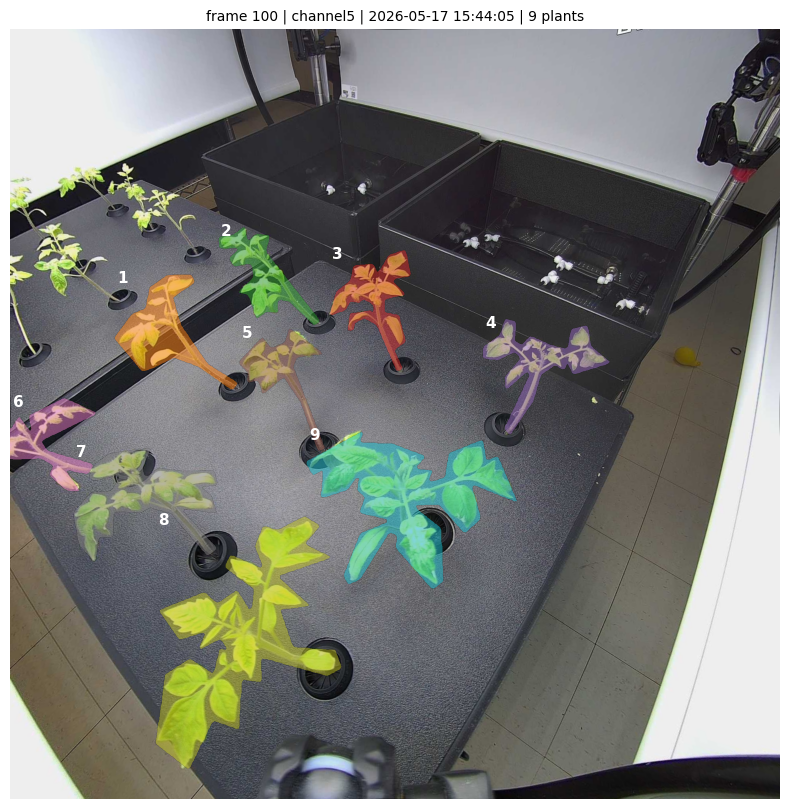

In [ ]:
show(100)
plt.show()

### Why de-fish first

The stored photos are raw fisheye (2560x1920); the masks live in the undistorted 1920x1920
frame. Drawing the mask on the raw photo makes it look shifted, which is expected.

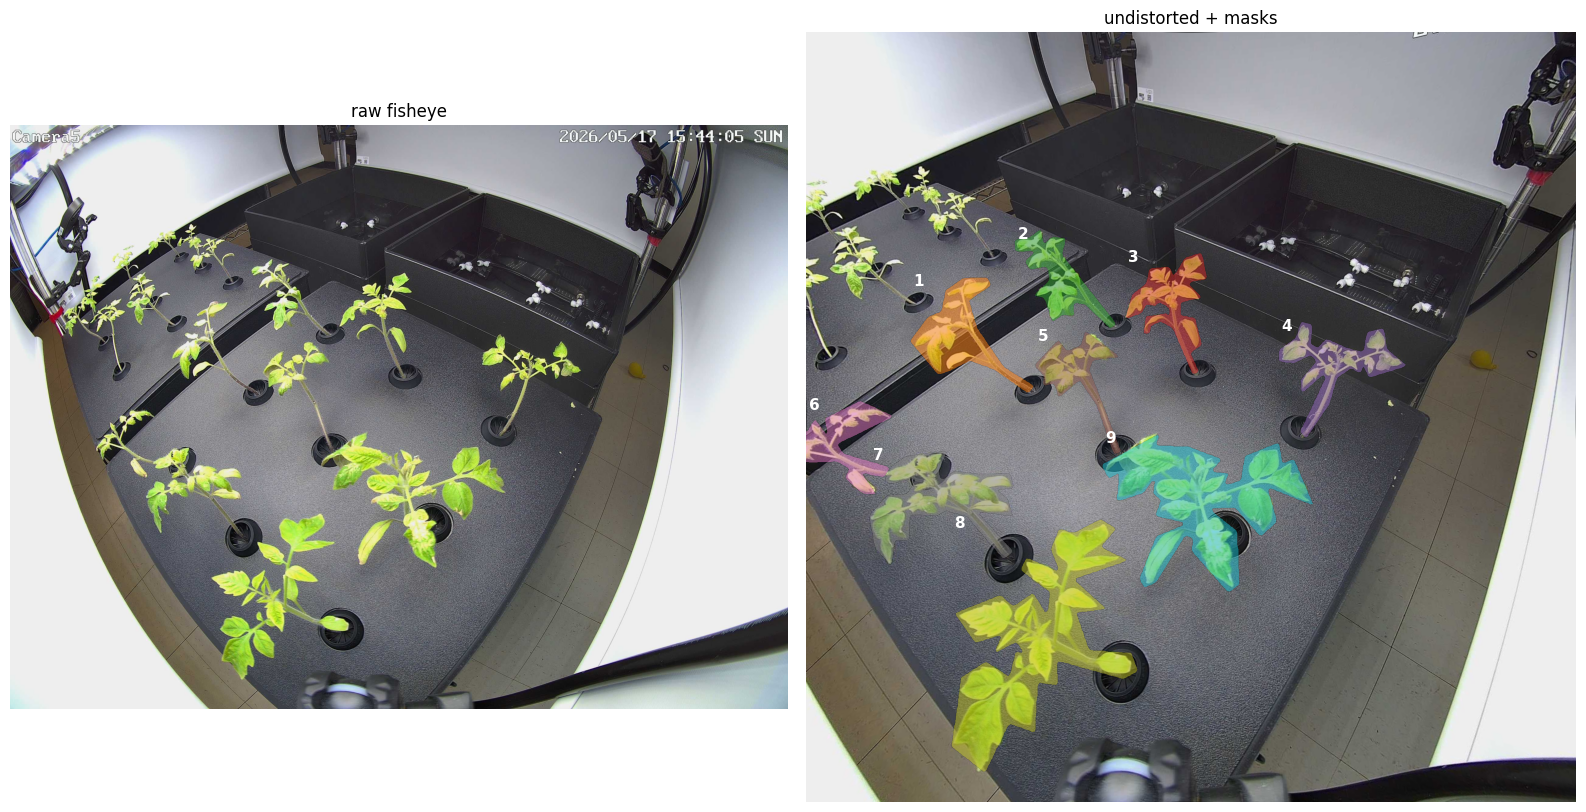

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

axes[0].imshow(images[100]["image"])
axes[0].set_title("raw fisheye")
axes[0].axis("off")

show(100, ax=axes[1])
axes[1].set_title("undistorted + masks")
plt.tight_layout()
plt.show()

# PUT YOUR CODE HERE

## Probably some code to use the segmentation data to calculate area for each plant

In [ ]:
import pandas as pd

rows = []
for i in range(100, 1000):  # only rows 100-999 have masks
    s = segs[i]
    for pid, area in zip(s["seg_ids"], s["seg_areas"]):
        rows.append({
            "frame_idx": i,
            "plant_id": pid,
            "area": area,
            "timestamp": f"{s['date']} {s['time']}",
        })

df = pd.DataFrame(rows)
print(df["timestamp"].head())  # check the format
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")
print("unparsed timestamps:", df["timestamp"].isna().sum())

# Fallback: if parsing fails, plot against frame_idx instead
X = "timestamp" if df["timestamp"].notna().all() else "frame_idx"
df.head()

0    2026-05-17 15:44:05
1    2026-05-17 15:44:05
2    2026-05-17 15:44:05
3    2026-05-17 15:44:05
4    2026-05-17 15:44:05
Name: timestamp, dtype: object
unparsed timestamps: 0


,frame_idx,plant_id,area,timestamp
0,100,1,31491,2026-05-17 15:44:05
1,100,2,21887,2026-05-17 15:44:05
2,100,3,24674,2026-05-17 15:44:05
3,100,4,28478,2026-05-17 15:44:05
4,100,5,19129,2026-05-17 15:44:05


## Some code to plot the area over time for each plant

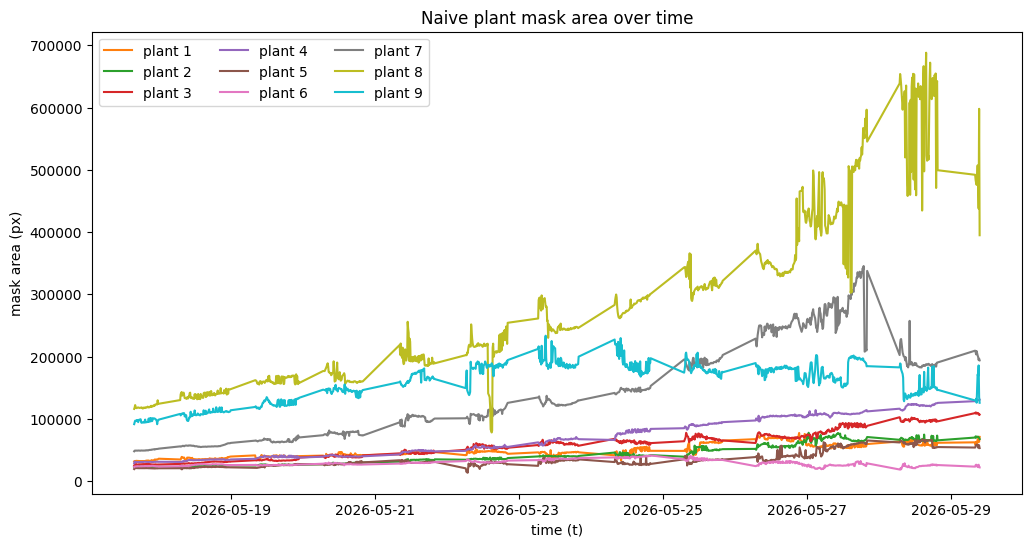

In [ ]:
fig, ax = plt.subplots(figsize=(12, 6))
for pid, g in df.groupby("plant_id"):
    g = g.sort_values(X)
    ax.plot(g[X], g["area"], label=f"plant {pid}", color=plt.cm.tab10(pid % 10))
ax.set_xlabel("time (t)")
ax.set_ylabel("mask area (px)")
ax.set_title("Naive plant mask area over time")
ax.legend(ncol=3)
plt.show()

If you want, instead of area, you can count the green pixels within the segmentation and plot that instead, keep both plots, it would be cool to see the difference

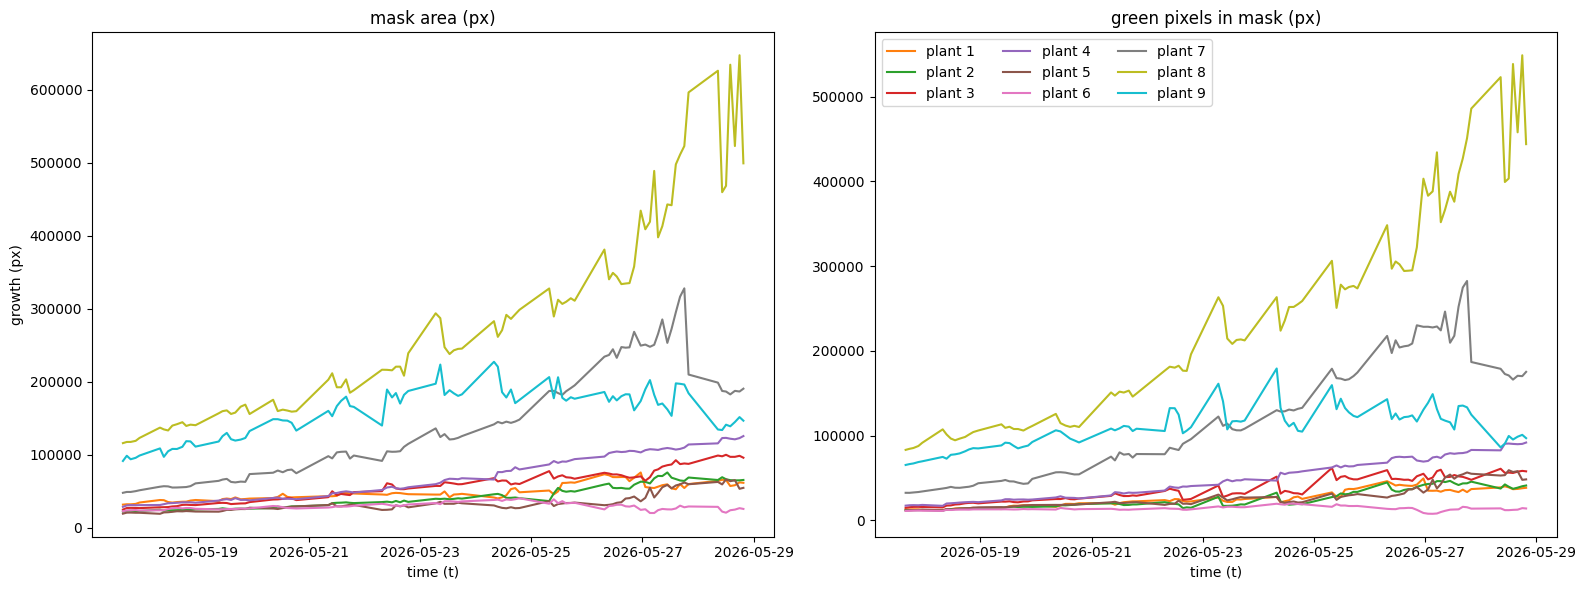

In [ ]:
EXG_THRESHOLD = 20   # placeholder: tune by looking at the debug image below
STEP = 10            # every 10th frame first (slow); lower it once it works

def green_mask(rgb, thr=EXG_THRESHOLD):
    r, g, b = [rgb[..., k].astype(np.int16) for k in range(3)]
    return (2 * g - r - b) > thr   # Excess Green index

green_rows = []
for i in range(100, 1000, STEP):
    s = segs[i]
    frame = undistort(images[i]["image"])   # RGB 1920x1920, same frame as the masks
    gm = green_mask(frame)
    for pid, rle in zip(s["seg_ids"], s["seg_rle"]):
        m = mask_utils.decode({"size": [1920, 1920], "counts": rle}).astype(bool)
        green_rows.append({
            "frame_idx": i,
            "plant_id": pid,
            "green_px": int((m & gm).sum()),
            "mask_px": int(m.sum()),
        })

gdf = pd.DataFrame(green_rows).merge(
    df[["frame_idx", "plant_id", "timestamp"]], on=["frame_idx", "plant_id"]
)

# Side-by-side: area vs green pixels
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharex=True)
for pid, g in gdf.groupby("plant_id"):
    g = g.sort_values(X)
    c = plt.cm.tab10(pid % 10)
    axes[0].plot(g[X], g["mask_px"], color=c, label=f"plant {pid}")
    axes[1].plot(g[X], g["green_px"], color=c, label=f"plant {pid}")
axes[0].set_title("mask area (px)")
axes[1].set_title("green pixels in mask (px)")
axes[0].set_ylabel("growth (px)")
for ax in axes:
    ax.set_xlabel("time (t)")
axes[1].legend(ncol=3)
plt.tight_layout()
plt.show()